# PCA Analysis — Employee Resignation Prediction

## Purpose

This notebook investigates whether Principal Component Analysis (PCA) can reduce the dimensionality of the numerical/ordinal features while retaining most of the information in the data.

### Main objectives
- Use only the **development dataset**. The final holdout set must remain untouched.
- Apply PCA to the **13 approved numerical/ordinal features**.
- Standardize the features before applying PCA.
- Examine how much variance each principal component explains.
- Find how many principal components are needed to retain:
  - 80% of the variance
  - 90% of the variance
  - 95% of the variance
- Examine the feature contributions (loadings) of the principal components.
- Visualize the data using PC1 and PC2.
- Compare Logistic Regression:
  - without PCA
  - with PCA
- Use the existing 5-fold cross-validation setup for a fair comparison.

> PCA is an unsupervised dimensionality-reduction technique. It does not use the `Resigned` target when creating the principal components.

## PCA Methodology and Leakage Rules

To keep the PCA analysis valid, the following rules will be followed:

1. **Use only the development partition**
   - The 20,000-row final holdout set will not be used anywhere in this notebook.

2. **Use only the 13 approved numerical/ordinal predictors for PCA**
   - Categorical features will not be included in the PCA transformation.

3. **Standardize the features before PCA**
   - PCA is affected by the scale of variables.
   - Therefore, `StandardScaler` will be applied before PCA.

4. **Do not use the target when fitting PCA**
   - PCA is an unsupervised technique.
   - The `Resigned` column is not used to calculate the principal components.

5. **Prevent data leakage during cross-validation**
   - When comparing Logistic Regression with and without PCA, scaling and PCA must be fitted only on the training folds.
   - This will be handled using a scikit-learn `Pipeline`.

6. **Use the existing fixed 5-fold split**
   - The folds created in `02_create_split_registry.ipynb` will be reused instead of creating new random folds.

In [1]:
# -----------------------------
# Cell 3: Imports and setup
# -----------------------------

# Path is used to create reliable file paths inside the project
from pathlib import Path

# pandas is used for loading and working with tabular data
import pandas as pd

# numpy is used for numerical calculations
import numpy as np

# matplotlib is used for graphs and visualizations
import matplotlib.pyplot as plt

# StandardScaler standardizes features before PCA
from sklearn.preprocessing import StandardScaler

# PCA performs dimensionality reduction
from sklearn.decomposition import PCA

# Logistic Regression will later be used to compare
# model performance with and without PCA
from sklearn.linear_model import LogisticRegression

# Pipeline allows scaling/PCA/model steps to be fitted safely
# inside each cross-validation fold
from sklearn.pipeline import Pipeline

# Metrics used later to compare the models
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score
)

# The notebook is inside the /notebooks folder,
# so ".." points to the main project folder
PROJECT_ROOT = Path("..").resolve()

print("Project root:", PROJECT_ROOT)

Project root: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project


In [2]:
# -----------------------------
# Cell 4: Load data and split registry
# -----------------------------

# Path to the original employee dataset
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

# Path to the fixed split created in Notebook 02
SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "split_registry.csv"
)

# Make sure both files actually exist before continuing
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
assert SPLIT_PATH.exists(), f"Split registry not found: {SPLIT_PATH}"

# Load the original dataset
df = pd.read_csv(DATA_PATH)

# Load the file that tells us which employees are
# development and which are final holdout
split_registry = pd.read_csv(SPLIT_PATH)

# Display basic information so we can confirm the files loaded correctly
print("Dataset shape:", df.shape)
print("Split registry shape:", split_registry.shape)

display(df.head())
display(split_registry.head())

Dataset shape: (100000, 20)
Split registry shape: (100000, 3)


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


,Employee_ID,partition,cv_fold
0,1,development,3.0
1,2,development,3.0
2,3,holdout,NaN
3,4,development,5.0
4,5,development,3.0


In [3]:
# -----------------------------
# Cell 5: Select development partition only
# -----------------------------

# Join the original dataset with the split information
# using Employee_ID as the common column.
data_with_split = df.merge(
    split_registry,
    on="Employee_ID",
    how="inner"
)

# Keep ONLY employees assigned to the development partition.
# The holdout employees must remain untouched in this notebook.
development_df = data_with_split[
    data_with_split["partition"] == "development"
].copy()

# Safety checks
# We expect exactly 80,000 development employees.
assert len(development_df) == 80000, (
    f"Expected 80,000 development rows, but found {len(development_df)}"
)

# Make sure no holdout rows accidentally entered our working data.
assert (development_df["partition"] == "development").all()

# Show the result
print("Development dataset shape:", development_df.shape)
print()
print("Partition counts:")
print(data_with_split["partition"].value_counts())

display(development_df.head())

Development dataset shape: (80000, 22)

Partition counts:
partition
development    80000
holdout        20000
Name: count, dtype: int64


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,...,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned,partition,cv_fold
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,...,22,2,0,14,66,0,2.63,False,development,3.0
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,...,13,14,100,12,61,2,1.72,False,development,3.0
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,...,28,12,100,10,0,1,1.86,False,development,5.0
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,...,29,13,100,15,9,1,1.25,False,development,3.0
6,7,IT,Male,37,Technician,2023-08-28 08:03:05.556036,1,Bachelor,5,5250.0,...,29,2,0,16,27,0,4.46,False,development,3.0


In [4]:
# -----------------------------
# Cell 6: Select PCA features
# -----------------------------

# These are the 13 approved numerical/ordinal predictors
# that we will use for PCA.
pca_features = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score"
]

# Select only these features from the 80,000-row development dataset.
X_pca = development_df[pca_features].copy()

# Safety checks
# PCA should receive exactly 13 features.
assert X_pca.shape[1] == 13

# Confirm that every expected feature exists.
assert list(X_pca.columns) == pca_features

# Show the shape and first few rows.
print("PCA input shape:", X_pca.shape)
print()
print("Features used for PCA:")

for feature in pca_features:
    print("-", feature)

display(X_pca.head())

PCA input shape: (80000, 13)

Features used for PCA:
- Age
- Years_At_Company
- Performance_Score
- Monthly_Salary
- Work_Hours_Per_Week
- Projects_Handled
- Overtime_Hours
- Sick_Days
- Remote_Work_Frequency
- Team_Size
- Training_Hours
- Promotions
- Employee_Satisfaction_Score


,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
0,55,2,5,6750.0,33,32,22,2,0,14,66,0,2.63
1,29,0,5,7500.0,34,34,13,14,100,12,61,2,1.72
3,48,7,2,4800.0,52,10,28,12,100,10,0,1,1.86
4,36,3,2,4800.0,38,11,29,13,100,15,9,1,1.25
6,37,1,5,5250.0,55,20,29,2,0,16,27,0,4.46


In [5]:
# -----------------------------
# Cell 7: Validate PCA input data
# -----------------------------

# PCA requires numerical values only.
# Check the data type of each selected feature.
print("Data types:")
print(X_pca.dtypes)

print("\nMissing values:")
print(X_pca.isnull().sum())

# Safety check:
# PCA cannot work directly with missing values.
assert X_pca.isnull().sum().sum() == 0, (
    "Missing values were found in the PCA features."
)

# Check that every selected PCA column is numeric.
non_numeric_columns = X_pca.select_dtypes(
    exclude=np.number
).columns.tolist()

assert len(non_numeric_columns) == 0, (
    f"Non-numeric columns found: {non_numeric_columns}"
)

print("\nValidation passed.")
print("All 13 PCA features are numeric and contain no missing values.")

Data types:
Age                              int64
Years_At_Company                 int64
Performance_Score                int64
Monthly_Salary                 float64
Work_Hours_Per_Week              int64
Projects_Handled                 int64
Overtime_Hours                   int64
Sick_Days                        int64
Remote_Work_Frequency            int64
Team_Size                        int64
Training_Hours                   int64
Promotions                       int64
Employee_Satisfaction_Score    float64
dtype: object

Missing values:
Age                            0
Years_At_Company               0
Performance_Score              0
Monthly_Salary                 0
Work_Hours_Per_Week            0
Projects_Handled               0
Overtime_Hours                 0
Sick_Days                      0
Remote_Work_Frequency          0
Team_Size                      0
Training_Hours                 0
Promotions                     0
Employee_Satisfaction_Score    0
dtype: int64

Validat

In [6]:
# -----------------------------
# Cell 8: Standardize PCA features
# -----------------------------

# Create the scaler.
# StandardScaler changes each feature so that it has:
# mean ≈ 0
# standard deviation ≈ 1
scaler = StandardScaler()

# Fit the scaler on the 80,000 development rows
# and transform the 13 PCA features.
X_scaled = scaler.fit_transform(X_pca)

# Convert the scaled NumPy array back into a DataFrame
# so the feature names are easier to inspect.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=pca_features,
    index=X_pca.index
)

print("Scaled data shape:", X_scaled_df.shape)

# Check the means after scaling.
# They should be very close to 0.
print("\nMeans after scaling:")
print(X_scaled_df.mean().round(4))

# Check the standard deviations after scaling.
# They should be very close to 1.
print("\nStandard deviations after scaling:")
print(X_scaled_df.std(ddof=0).round(4))

Scaled data shape: (80000, 13)

Means after scaling:
Age                            0.0
Years_At_Company              -0.0
Performance_Score              0.0
Monthly_Salary                 0.0
Work_Hours_Per_Week            0.0
Projects_Handled               0.0
Overtime_Hours                 0.0
Sick_Days                      0.0
Remote_Work_Frequency         -0.0
Team_Size                      0.0
Training_Hours                -0.0
Promotions                    -0.0
Employee_Satisfaction_Score   -0.0
dtype: float64

Standard deviations after scaling:
Age                            1.0
Years_At_Company               1.0
Performance_Score              1.0
Monthly_Salary                 1.0
Work_Hours_Per_Week            1.0
Projects_Handled               1.0
Overtime_Hours                 1.0
Sick_Days                      1.0
Remote_Work_Frequency          1.0
Team_Size                      1.0
Training_Hours                 1.0
Promotions                     1.0
Employee_Satisfaction

In [7]:
# -----------------------------
# Cell 9: Fit PCA
# -----------------------------

# Create the PCA object.
# We do not set n_components yet because we first want
# to inspect all 13 possible principal components.
pca = PCA()

# Fit PCA on the standardized development data
# and transform the data into principal components.
X_pca_transformed = pca.fit_transform(X_scaled_df)

# Create readable names for the components:
# PC1, PC2, PC3, ..., PC13
pc_names = [
    f"PC{i+1}"
    for i in range(X_pca_transformed.shape[1])
]

# Convert the PCA output into a DataFrame
# so it is easier to inspect.
pca_df = pd.DataFrame(
    X_pca_transformed,
    columns=pc_names,
    index=X_scaled_df.index
)

print("PCA output shape:", pca_df.shape)
print()
print("Principal components created:")
print(pc_names)

display(pca_df.head())

PCA output shape: (80000, 13)

Principal components created:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13']


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,1.199071,0.811901,0.374455,0.649633,0.929057,0.570633,0.804095,1.690451,-1.044434,-1.765959,0.377317,-0.778883,0.810880
1,1.595943,-1.339322,-0.830503,1.255241,-1.212712,-1.724312,0.325029,0.779403,-1.205042,1.070557,-0.421330,1.048046,0.426462
3,-1.345895,0.337650,1.553931,0.139667,-1.290704,0.687800,-1.004490,0.189682,0.512220,1.648388,1.496055,1.201329,0.338556
4,-1.324032,-0.473180,0.852630,0.849380,-1.663699,-0.456847,-0.995960,1.605576,-0.619499,1.545872,1.564661,0.562681,0.328703
6,0.355423,1.208652,0.661384,-1.308032,1.252487,-1.147658,-1.039787,0.673009,-0.100477,-1.515449,1.759076,-0.765739,1.606907


In [8]:
# -----------------------------
# Cell 10: Explained variance
# -----------------------------

# This tells us how much of the total information/variance
# is captured by each principal component.
explained_variance_ratio = pca.explained_variance_ratio_

# Put the results into a readable table.
explained_variance_df = pd.DataFrame({
    "Principal_Component": pc_names,
    "Explained_Variance_Ratio": explained_variance_ratio,
    "Explained_Variance_Percent": explained_variance_ratio * 100
})

# Add cumulative explained variance.
# This shows how much information is retained when
# we keep PC1, then PC1+PC2, then PC1+PC2+PC3, etc.
explained_variance_df["Cumulative_Variance_Percent"] = (
    explained_variance_df["Explained_Variance_Percent"].cumsum()
)

display(explained_variance_df.round(4))

,Principal_Component,Explained_Variance_Ratio,Explained_Variance_Percent,Cumulative_Variance_Percent
0,PC1,0.1162,11.6175,11.6175
1,PC2,0.0784,7.8441,19.4616
2,PC3,0.0781,7.8066,27.2682
3,PC4,0.0775,7.7547,35.0229
4,PC5,0.0774,7.7439,42.7668
5,PC6,0.0771,7.7126,50.4794
6,PC7,0.0769,7.6897,58.1691
7,PC8,0.0767,7.6711,65.8402
8,PC9,0.0763,7.6297,73.4700
9,PC10,0.0761,7.6074,81.0774


In [9]:
# -----------------------------
# Cell 11: Components needed for variance thresholds
# -----------------------------

# Calculate cumulative explained variance as a decimal.
# Example:
# 0.80 = 80%
# 0.90 = 90%
# 0.95 = 95%
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the minimum number of principal components needed
# to reach each variance threshold.
components_80 = np.argmax(cumulative_variance >= 0.80) + 1
components_90 = np.argmax(cumulative_variance >= 0.90) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed to retain at least 80% variance:", components_80)
print("Components needed to retain at least 90% variance:", components_90)
print("Components needed to retain at least 95% variance:", components_95)

Components needed to retain at least 80% variance: 10
Components needed to retain at least 90% variance: 12
Components needed to retain at least 95% variance: 12


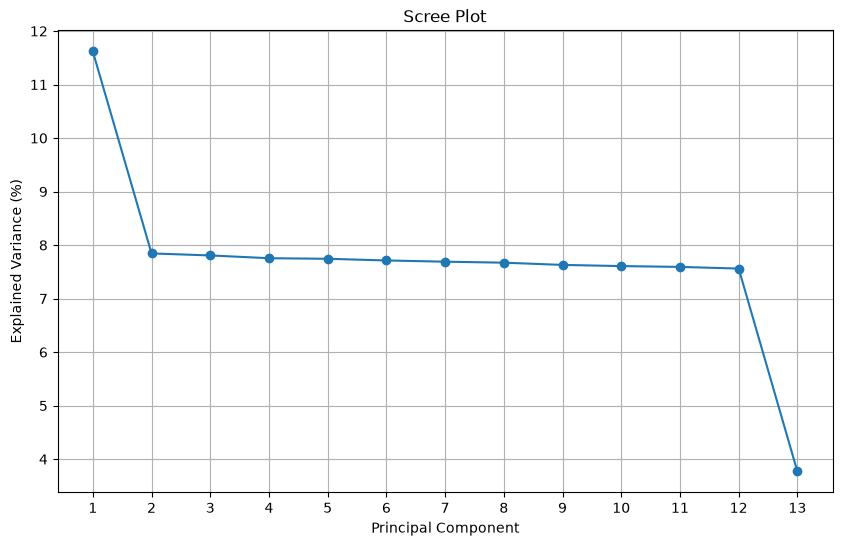

In [10]:
# -----------------------------
# Cell 12: Scree plot
# -----------------------------

# A scree plot shows how much variance each principal component explains.
# It helps us see whether the first few PCs capture most of the information.

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio * 100,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Scree Plot")

# Show PC numbers from 1 to 13 on the x-axis
plt.xticks(range(1, len(explained_variance_ratio) + 1))

plt.grid(True)

plt.show()


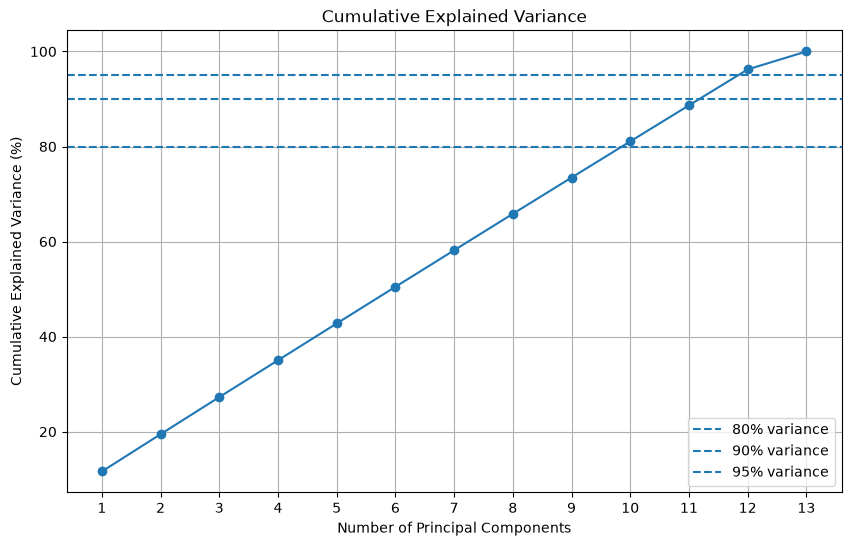

In [11]:
# -----------------------------
# Cell 13: Cumulative explained variance plot
# -----------------------------

# Cumulative variance shows how much total information
# is retained as we keep more principal components.

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

# Add reference lines for the common thresholds
plt.axhline(y=80, linestyle="--", label="80% variance")
plt.axhline(y=90, linestyle="--", label="90% variance")
plt.axhline(y=95, linestyle="--", label="95% variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")

plt.xticks(range(1, len(cumulative_variance) + 1))

plt.grid(True)
plt.legend()

plt.show()

In [12]:
# -----------------------------
# Cell 14: Principal component loadings
# -----------------------------

# PCA loadings show how strongly each original feature
# contributes to each principal component.
#
# A larger absolute value means that feature has
# a stronger influence on that principal component.

loadings_df = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=pc_names
)

print("PCA loadings:")
display(loadings_df.round(4))

PCA loadings:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
Age,0.0076,0.0737,0.4292,0.2279,0.1675,0.3851,0.5173,0.1338,0.3235,-0.2380,0.1041,0.3525,0.0019
Years_At_Company,0.0013,0.4431,-0.1341,-0.0034,-0.0735,0.5581,-0.0604,-0.1817,0.3136,0.4951,-0.1615,-0.2501,0.0018
Performance_Score,0.7069,0.0051,-0.0021,-0.0076,-0.0016,0.0000,-0.0072,-0.0059,-0.0079,-0.0043,0.0051,0.0038,0.7071
Monthly_Salary,0.7069,0.0057,-0.0027,-0.0146,-0.0015,-0.0027,-0.0052,-0.0039,0.0044,-0.0014,0.0100,0.0051,-0.7070
Work_Hours_Per_Week,-0.0177,0.3570,0.1430,-0.4563,-0.1925,-0.2046,-0.2587,-0.3828,0.3301,-0.2630,-0.0296,0.4149,0.0045
Projects_Handled,-0.0003,0.3711,-0.3773,0.1644,0.4740,-0.0410,-0.0271,0.0932,-0.2978,0.0488,-0.3341,0.5044,-0.0035
Overtime_Hours,-0.0089,0.5363,0.2807,0.0567,-0.0456,-0.1235,0.0340,0.0063,-0.4362,0.1950,0.6182,-0.0366,-0.0012
Sick_Days,0.0114,-0.0125,0.4973,0.3073,-0.1171,-0.4491,-0.0512,0.0737,0.1410,0.4990,-0.3905,0.1145,0.0002
Remote_Work_Frequency,-0.0008,-0.2384,-0.3082,0.5405,-0.2626,0.0459,-0.2047,-0.2951,0.1555,0.1404,0.3903,0.3997,-0.0001
Team_Size,0.0008,0.2825,-0.3296,0.0631,-0.1487,-0.2909,-0.0108,0.6605,0.4707,-0.0764,0.1749,-0.0803,0.0059


In [13]:
# -----------------------------
# Cell 15: Interpret PC1, PC2, and PC3
# -----------------------------

# We will inspect the features with the largest absolute loadings.
# The absolute value tells us how strongly a feature contributes,
# regardless of whether the direction is positive or negative.

for pc in ["PC1", "PC2", "PC3"]:

    print(f"\nTop contributors to {pc}:")

    # Sort features by the absolute size of their loading
    top_features = (
        loadings_df[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    # Show the original signed loading as well
    result = pd.DataFrame({
        "Absolute_Loading": top_features,
        "Original_Loading": loadings_df.loc[top_features.index, pc]
    })

    display(result.round(4))


Top contributors to PC1:


,Absolute_Loading,Original_Loading
Performance_Score,0.7069,0.7069
Monthly_Salary,0.7069,0.7069
Work_Hours_Per_Week,0.0177,-0.0177
Sick_Days,0.0114,0.0114
Overtime_Hours,0.0089,-0.0089



Top contributors to PC2:


,Absolute_Loading,Original_Loading
Overtime_Hours,0.5363,0.5363
Years_At_Company,0.4431,0.4431
Projects_Handled,0.3711,0.3711
Work_Hours_Per_Week,0.3570,0.3570
Training_Hours,0.2933,0.2933



Top contributors to PC3:


,Absolute_Loading,Original_Loading
Sick_Days,0.4973,0.4973
Age,0.4292,0.4292
Projects_Handled,0.3773,-0.3773
Team_Size,0.3296,-0.3296
Remote_Work_Frequency,0.3082,-0.3082


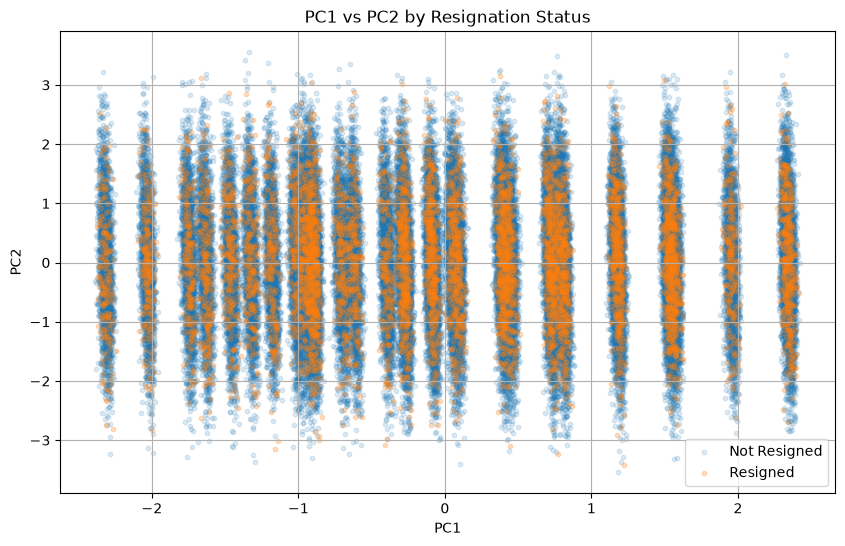

In [14]:
# -----------------------------
# Cell 16: PC1 vs PC2 visualization
# -----------------------------

# Add the Resigned target only for visualization.
# IMPORTANT:
# The target was NOT used to create the principal components.
pca_plot_df = pca_df[["PC1", "PC2"]].copy()
pca_plot_df["Resigned"] = development_df.loc[
    pca_plot_df.index,
    "Resigned"
].astype(int)

plt.figure(figsize=(10, 6))

# Plot employees who did not resign
not_resigned = pca_plot_df[pca_plot_df["Resigned"] == 0]

plt.scatter(
    not_resigned["PC1"],
    not_resigned["PC2"],
    alpha=0.15,
    s=10,
    label="Not Resigned"
)

# Plot employees who resigned
resigned = pca_plot_df[pca_plot_df["Resigned"] == 1]

plt.scatter(
    resigned["PC1"],
    resigned["PC2"],
    alpha=0.25,
    s=10,
    label="Resigned"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PC1 vs PC2 by Resignation Status")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# -----------------------------
# Cell 17: Prepare target and CV folds
# -----------------------------

# Target variable:
# False = employee did not resign
# True  = employee resigned
y = development_df["Resigned"].astype(int)

# These fold numbers were already created in Notebook 02.
# We will reuse them instead of making new random folds.
cv_folds = development_df["cv_fold"].astype(int)

# Safety checks
assert len(y) == 80000
assert len(cv_folds) == 80000

# We expect exactly 5 folds: 1, 2, 3, 4, 5
assert sorted(cv_folds.unique().tolist()) == [1, 2, 3, 4, 5]

print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nRows in each CV fold:")
print(cv_folds.value_counts().sort_index())

Target shape: (80000,)

Target distribution:
Resigned
0    71992
1     8008
Name: count, dtype: int64

Target percentages:
Resigned
0    89.99
1    10.01
Name: proportion, dtype: float64

Rows in each CV fold:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000
Name: count, dtype: int64


In [16]:
# -----------------------------
# Cell 18: Logistic Regression WITHOUT PCA
# -----------------------------

# Create an empty array where we will store the prediction
# probability for every development employee.
#
# These will be out-of-fold (OOF) predictions:
# each employee is predicted by a model that was NOT trained on that employee.
oof_prob_no_pca = np.zeros(len(X_pca))

# Run through the 5 fixed folds created in Notebook 02.
for fold in range(1, 6):

    print(f"Running Fold {fold}...")

    # Convert the fixed fold assignments into True/False masks.
    #
    # Training rows = every fold except the current fold
    # Validation rows = current fold only
    train_mask = cv_folds.to_numpy() != fold
    val_mask = cv_folds.to_numpy() == fold

    # Split the 13 original numerical/ordinal features.
    X_train = X_pca.iloc[train_mask]
    X_val = X_pca.iloc[val_mask]

    # Split the target in exactly the same way.
    y_train = y.iloc[train_mask]

    # Build the model pipeline.
    #
    # IMPORTANT:
    # StandardScaler is INSIDE the pipeline.
    # This means the scaler is fitted only on the training fold,
    # which prevents information leaking from the validation fold.
    model_no_pca = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    # Train using only the training folds.
    model_no_pca.fit(X_train, y_train)

    # Predict the probability that each validation employee resigned.
    val_probabilities = model_no_pca.predict_proba(X_val)[:, 1]

    # Store those probabilities in their correct positions.
    oof_prob_no_pca[val_mask] = val_probabilities


# Safety check:
# Every employee should now have received one OOF probability.
assert len(oof_prob_no_pca) == 80000

print("\nCompleted 5-fold Logistic Regression WITHOUT PCA.")
print("OOF predictions created:", len(oof_prob_no_pca))

print(
    "Probability range:",
    round(oof_prob_no_pca.min(), 4),
    "to",
    round(oof_prob_no_pca.max(), 4)
)

Running Fold 1...
Running Fold 2...
Running Fold 3...
Running Fold 4...
Running Fold 5...

Completed 5-fold Logistic Regression WITHOUT PCA.
OOF predictions created: 80000
Probability range: 0.0864 to 0.1144


In [17]:
# -----------------------------
# Cell 19: Logistic Regression WITH PCA
# -----------------------------

# Create an empty array for the out-of-fold probabilities.
oof_prob_with_pca = np.zeros(len(X_pca))

# Store how many principal components PCA keeps in each fold.
components_per_fold = []

# Use the same fixed 5 folds as before.
for fold in range(1, 6):

    print(f"Running Fold {fold}...")

    # Training = all folds except the current fold
    # Validation = current fold
    train_mask = cv_folds.to_numpy() != fold
    val_mask = cv_folds.to_numpy() == fold

    X_train = X_pca.iloc[train_mask]
    X_val = X_pca.iloc[val_mask]

    y_train = y.iloc[train_mask]

    # Build the PCA pipeline.
    #
    # IMPORTANT:
    # StandardScaler and PCA are both INSIDE the pipeline.
    #
    # Therefore, for each fold:
    # 1. scaler is fitted only on training data
    # 2. PCA is fitted only on training data
    # 3. Logistic Regression is trained only on training data
    #
    # This prevents data leakage.
    model_with_pca = Pipeline([
        ("scaler", StandardScaler()),

        # Keep enough PCs to explain at least 95% of variance
        ("pca", PCA(n_components=0.95)),

        ("logistic_regression", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    # Train the entire pipeline on the training folds.
    model_with_pca.fit(X_train, y_train)

    # Record how many PCs were selected in this fold.
    number_of_components = (
        model_with_pca
        .named_steps["pca"]
        .n_components_
    )

    components_per_fold.append(number_of_components)

    print(
        f"  PCA kept {number_of_components} components"
    )

    # Predict resignation probabilities for the validation fold.
    val_probabilities = model_with_pca.predict_proba(X_val)[:, 1]

    # Store the out-of-fold predictions.
    oof_prob_with_pca[val_mask] = val_probabilities


# Safety check
assert len(oof_prob_with_pca) == 80000

print("\nCompleted 5-fold Logistic Regression WITH PCA.")
print("OOF predictions created:", len(oof_prob_with_pca))

print(
    "Probability range:",
    round(oof_prob_with_pca.min(), 4),
    "to",
    round(oof_prob_with_pca.max(), 4)
)

print("\nPCA components kept in each fold:")
print(components_per_fold)

Running Fold 1...
  PCA kept 12 components
Running Fold 2...
  PCA kept 12 components
Running Fold 3...
  PCA kept 12 components
Running Fold 4...
  PCA kept 12 components
Running Fold 5...
  PCA kept 12 components

Completed 5-fold Logistic Regression WITH PCA.
OOF predictions created: 80000
Probability range: 0.0878 to 0.1135

PCA components kept in each fold:
[np.int64(12), np.int64(12), np.int64(12), np.int64(12), np.int64(12)]


In [18]:
# -----------------------------
# Cell 20: Compare Logistic Regression metrics
# -----------------------------

# Convert the true target to a NumPy array
# so it matches the OOF prediction arrays.
y_true = y.to_numpy()

# Convert probabilities into class predictions
# using the standard threshold of 0.5.
pred_no_pca = (oof_prob_no_pca >= 0.5).astype(int)
pred_with_pca = (oof_prob_with_pca >= 0.5).astype(int)

# Calculate the evaluation metrics for both models.
results = pd.DataFrame({
    "Model": [
        "Logistic Regression - No PCA",
        "Logistic Regression - With PCA"
    ],

    # PR-AUC is the main metric for this project
    # because the target is imbalanced (~10% resigned).
    "PR_AUC": [
        average_precision_score(y_true, oof_prob_no_pca),
        average_precision_score(y_true, oof_prob_with_pca)
    ],

    "ROC_AUC": [
        roc_auc_score(y_true, oof_prob_no_pca),
        roc_auc_score(y_true, oof_prob_with_pca)
    ],

    # Lower Brier Score is better.
    "Brier_Score": [
        brier_score_loss(y_true, oof_prob_no_pca),
        brier_score_loss(y_true, oof_prob_with_pca)
    ],

    "Precision": [
        precision_score(y_true, pred_no_pca, zero_division=0),
        precision_score(y_true, pred_with_pca, zero_division=0)
    ],

    "Recall": [
        recall_score(y_true, pred_no_pca, zero_division=0),
        recall_score(y_true, pred_with_pca, zero_division=0)
    ],

    "F1": [
        f1_score(y_true, pred_no_pca, zero_division=0),
        f1_score(y_true, pred_with_pca, zero_division=0)
    ]
})

display(results.round(4))

,Model,PR_AUC,ROC_AUC,Brier_Score,Precision,Recall,F1
0,Logistic Regression - No PCA,0.1003,0.4999,0.0901,0.0,0.0,0.0
1,Logistic Regression - With PCA,0.0997,0.4997,0.0901,0.0,0.0,0.0


In [19]:
# -----------------------------
# Cell 21: Save PCA results
# -----------------------------

# Create the PCA results folder if it does not already exist.
PCA_RESULTS_DIR = PROJECT_ROOT / "results" / "pca"
PCA_RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# 1. Save explained variance for every principal component.
explained_variance_df.to_csv(
    PCA_RESULTS_DIR / "explained_variance.csv",
    index=False
)


# 2. Save the PCA loadings.
#
# This tells us how strongly each original feature contributes
# to each principal component.
loadings_df.to_csv(
    PCA_RESULTS_DIR / "pca_loadings.csv"
)


# 3. Save the Logistic Regression comparison.
results.to_csv(
    PCA_RESULTS_DIR / "logistic_regression_pca_comparison.csv",
    index=False
)


# 4. Save a short PCA summary.
pca_summary = pd.DataFrame({
    "Measure": [
        "Original numerical/ordinal features",
        "Components for >=80% variance",
        "Components for >=90% variance",
        "Components for >=95% variance"
    ],
    "Value": [
        len(pca_features),
        components_80,
        components_90,
        components_95
    ]
})

pca_summary.to_csv(
    PCA_RESULTS_DIR / "pca_summary.csv",
    index=False
)


print("PCA results saved to:")
print(PCA_RESULTS_DIR)

print("\nSaved files:")
for file in sorted(PCA_RESULTS_DIR.glob("*.csv")):
    print("-", file.name)

PCA results saved to:
E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\pca

Saved files:
- explained_variance.csv
- logistic_regression_pca_comparison.csv
- pca_loadings.csv
- pca_summary.csv


## PCA Conclusion

The PCA analysis was performed using only the **80,000-row development partition** and the **13 approved numerical/ordinal predictors**. The formal holdout set was not used for this analysis.

### Main findings

- PCA was applied after standardizing the 13 numerical/ordinal features.
- The explained variance was spread across many principal components rather than being concentrated in only a few components.
- The number of components required to retain the original variance was:
  - **80% variance:** 10 components
  - **90% variance:** 12 components
  - **95% variance:** 12 components
- Therefore, retaining at least 95% of the variance reduced the feature space only from **13 original features to 12 principal components**.
- This indicates that PCA provides only limited dimensionality reduction for these features.

### Principal component interpretation

- **PC1** was dominated mainly by `Performance_Score` and `Monthly_Salary`.
- Other principal components represented different combinations of workload, experience, attendance, satisfaction, promotions, team size, and related numerical characteristics.
- The PC1 vs PC2 visualization showed substantial overlap between resigned and non-resigned employees, so the first two components did not provide clear visual separation between the two classes.

### Logistic Regression comparison

Using the existing fixed 5-fold cross-validation setup:

| Model | PR-AUC | ROC-AUC | Brier Score |
|---|---:|---:|---:|
| Logistic Regression without PCA | 0.1003 | 0.4999 | 0.0901 |
| Logistic Regression with PCA | 0.0997 | 0.4997 | 0.0901 |

The Logistic Regression model without PCA performed slightly better in PR-AUC and ROC-AUC, although the difference was very small.

Both models performed close to a no-skill level, indicating that Logistic Regression using these 13 numerical/ordinal predictors did not identify a strong linear resignation signal.

At the default classification threshold of 0.5, both models produced zero precision, recall, and F1 because their predicted resignation probabilities remained well below 0.5.

### Final decision

PCA did **not** improve Logistic Regression performance in this experiment.

Because PCA reduced 13 features to only 12 components at the 95% variance level and slightly reduced predictive performance, there is currently no evidence that PCA should be applied automatically to the main advanced models.

The six main project models should therefore continue using their intended preprocessing strategies unless a model-specific experiment later demonstrates a benefit from PCA.

In [20]:
# -----------------------------
# Cell 23: Final PCA notebook checks
# -----------------------------

# Confirm that only the development partition was analysed.
assert len(development_df) == 80000
assert (development_df["partition"] == "development").all()

# Confirm that PCA used exactly 13 approved numerical/ordinal features.
assert X_pca.shape == (80000, 13)

# Confirm the variance thresholds obtained earlier.
assert components_80 == 10
assert components_90 == 12
assert components_95 == 12

# Confirm that both Logistic Regression experiments
# produced one out-of-fold probability for every development employee.
assert len(oof_prob_no_pca) == 80000
assert len(oof_prob_with_pca) == 80000

# Confirm that all expected result files were saved.
expected_files = [
    "explained_variance.csv",
    "pca_loadings.csv",
    "logistic_regression_pca_comparison.csv",
    "pca_summary.csv"
]

for filename in expected_files:
    file_path = PCA_RESULTS_DIR / filename
    assert file_path.exists(), f"Missing result file: {filename}"

print("All final PCA checks passed.")
print("PCA notebook is complete.")

All final PCA checks passed.
PCA notebook is complete.


In [21]:
# -----------------------------
# Cell 24: Logistic Regression WITH PCA (80% variance)
# -----------------------------

# Create an empty array for the new out-of-fold probabilities.
oof_prob_pca_80 = np.zeros(len(X_pca))

# Store how many principal components PCA keeps in each fold.
components_per_fold_80 = []

# Reuse the same fixed 5 folds.
for fold in range(1, 6):

    print(f"Running Fold {fold}...")

    # Training = all folds except the current fold
    # Validation = current fold
    train_mask = cv_folds.to_numpy() != fold
    val_mask = cv_folds.to_numpy() == fold

    X_train = X_pca.iloc[train_mask]
    X_val = X_pca.iloc[val_mask]

    y_train = y.iloc[train_mask]

    # Build the pipeline.
    #
    # This time PCA keeps enough components
    # to retain at least 80% of the variance.
    model_pca_80 = Pipeline([
        ("scaler", StandardScaler()),

        ("pca", PCA(n_components=0.80)),

        ("logistic_regression", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    # Fit only on the training folds.
    model_pca_80.fit(X_train, y_train)

    # Record how many components PCA kept.
    number_of_components = (
        model_pca_80
        .named_steps["pca"]
        .n_components_
    )

    components_per_fold_80.append(number_of_components)

    print(
        f"  PCA kept {number_of_components} components"
    )

    # Predict resignation probabilities for the validation fold.
    val_probabilities = model_pca_80.predict_proba(X_val)[:, 1]

    # Store the out-of-fold predictions.
    oof_prob_pca_80[val_mask] = val_probabilities


# Safety check
assert len(oof_prob_pca_80) == 80000

print("\nCompleted 5-fold Logistic Regression WITH PCA at 80% variance.")
print("OOF predictions created:", len(oof_prob_pca_80))

print(
    "Probability range:",
    round(oof_prob_pca_80.min(), 4),
    "to",
    round(oof_prob_pca_80.max(), 4)
)

print("\nPCA components kept in each fold:")
print(components_per_fold_80)

Running Fold 1...
  PCA kept 10 components
Running Fold 2...
  PCA kept 10 components
Running Fold 3...
  PCA kept 10 components
Running Fold 4...
  PCA kept 10 components
Running Fold 5...
  PCA kept 10 components

Completed 5-fold Logistic Regression WITH PCA at 80% variance.
OOF predictions created: 80000
Probability range: 0.0889 to 0.1121

PCA components kept in each fold:
[np.int64(10), np.int64(10), np.int64(10), np.int64(10), np.int64(10)]


In [22]:
# -----------------------------
# Cell 25: Compare all three Logistic Regression versions
# -----------------------------

# Convert the 80% PCA probabilities into class predictions
# using the same 0.5 threshold as before.
pred_pca_80 = (oof_prob_pca_80 >= 0.5).astype(int)

# Build one comparison table for all three models.
results_all = pd.DataFrame({
    "Model": [
        "Logistic Regression - No PCA",
        "Logistic Regression - PCA 95%",
        "Logistic Regression - PCA 80%"
    ],

    # Main project metric
    "PR_AUC": [
        average_precision_score(y_true, oof_prob_no_pca),
        average_precision_score(y_true, oof_prob_with_pca),
        average_precision_score(y_true, oof_prob_pca_80)
    ],

    "ROC_AUC": [
        roc_auc_score(y_true, oof_prob_no_pca),
        roc_auc_score(y_true, oof_prob_with_pca),
        roc_auc_score(y_true, oof_prob_pca_80)
    ],

    # Lower is better
    "Brier_Score": [
        brier_score_loss(y_true, oof_prob_no_pca),
        brier_score_loss(y_true, oof_prob_with_pca),
        brier_score_loss(y_true, oof_prob_pca_80)
    ],

    "Precision": [
        precision_score(y_true, pred_no_pca, zero_division=0),
        precision_score(y_true, pred_with_pca, zero_division=0),
        precision_score(y_true, pred_pca_80, zero_division=0)
    ],

    "Recall": [
        recall_score(y_true, pred_no_pca, zero_division=0),
        recall_score(y_true, pred_with_pca, zero_division=0),
        recall_score(y_true, pred_pca_80, zero_division=0)
    ],

    "F1": [
        f1_score(y_true, pred_no_pca, zero_division=0),
        f1_score(y_true, pred_with_pca, zero_division=0),
        f1_score(y_true, pred_pca_80, zero_division=0)
    ]
})

display(results_all.round(4))

,Model,PR_AUC,ROC_AUC,Brier_Score,Precision,Recall,F1
0,Logistic Regression - No PCA,0.1003,0.4999,0.0901,0.0,0.0,0.0
1,Logistic Regression - PCA 95%,0.0997,0.4997,0.0901,0.0,0.0,0.0
2,Logistic Regression - PCA 80%,0.0998,0.5001,0.0901,0.0,0.0,0.0


In [23]:
# -----------------------------
# Cell 26: Update saved PCA comparison
# -----------------------------

# Save the updated comparison containing all three models:
# 1. Logistic Regression without PCA
# 2. Logistic Regression with PCA at 95% variance
# 3. Logistic Regression with PCA at 80% variance

results_all.to_csv(
    PCA_RESULTS_DIR / "logistic_regression_pca_comparison.csv",
    index=False
)

print("Updated comparison file saved:")
print(
    PCA_RESULTS_DIR
    / "logistic_regression_pca_comparison.csv"
)

print("\nModels included:")
for model in results_all["Model"]:
    print("-", model)

Updated comparison file saved:
E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\pca\logistic_regression_pca_comparison.csv

Models included:
- Logistic Regression - No PCA
- Logistic Regression - PCA 95%
- Logistic Regression - PCA 80%


## Final PCA Conclusion

The PCA analysis was performed using only the **80,000-row development partition** and the **13 approved numerical/ordinal predictors**. The formal holdout set was not used.

### Main PCA findings

- PCA was applied after standardizing the 13 numerical/ordinal features.
- The explained variance was distributed across many principal components rather than being concentrated in only a few.
- Components required to retain the original variance:
  - **80% variance:** 10 components
  - **90% variance:** 12 components
  - **95% variance:** 12 components
- Therefore:
  - 80% PCA reduced the feature space from **13 features to 10 components**
  - 95% PCA reduced the feature space from **13 features to 12 components**

This shows that PCA provides only limited dimensionality reduction for this dataset.

### Principal component interpretation

- **PC1** was mainly influenced by `Performance_Score` and `Monthly_Salary`.
- Other components represented combinations of workload, experience, attendance, satisfaction, promotions, team size, and related employee characteristics.
- The PC1 vs PC2 visualization showed substantial overlap between resigned and non-resigned employees.
- Therefore, the first two principal components did not clearly separate the two resignation classes.

### Logistic Regression comparison

The same fixed 5-fold cross-validation setup was used for all three experiments.

| Model | Dimensions | PR-AUC | ROC-AUC | Brier Score |
|---|---:|---:|---:|---:|
| Logistic Regression without PCA | 13 features | 0.1003 | 0.4999 | 0.0901 |
| Logistic Regression with PCA 95% | 12 PCs | 0.0997 | 0.4997 | 0.0901 |
| Logistic Regression with PCA 80% | 10 PCs | 0.0998 | 0.5001 | 0.0901 |

The model without PCA achieved the highest PR-AUC.

Both PCA versions produced slightly lower PR-AUC values, while ROC-AUC remained approximately 0.50 for all models.

This indicates that Logistic Regression using these numerical/ordinal predictors did not identify a strong linear resignation signal.

At the default classification threshold of 0.5, all three models produced zero precision, recall, and F1 because their predicted resignation probabilities remained below 0.5.

### Final decision

PCA did **not** improve Logistic Regression performance.

The 95% PCA version provided almost no dimensionality reduction, while the more aggressive 80% PCA version reduced the data to 10 components but still did not improve predictive performance.

Therefore, there is currently no evidence that PCA should be used as a default preprocessing step for the six main advanced models.

The main models should continue using their intended preprocessing strategies unless a future model-specific experiment provides evidence that PCA is beneficial.

In [24]:
# -----------------------------
# Cell 27: Final checks after all PCA experiments
# -----------------------------

# Confirm the development data is still the only partition analysed.
assert len(development_df) == 80000
assert (development_df["partition"] == "development").all()

# Confirm PCA used the 13 intended numerical/ordinal features.
assert X_pca.shape == (80000, 13)

# Confirm the variance thresholds.
assert components_80 == 10
assert components_90 == 12
assert components_95 == 12

# Confirm every model produced one OOF probability
# for every development employee.
assert len(oof_prob_no_pca) == 80000
assert len(oof_prob_with_pca) == 80000
assert len(oof_prob_pca_80) == 80000

# Confirm PCA selected the expected number of components
# consistently across all five folds.
assert all(int(x) == 12 for x in components_per_fold)
assert all(int(x) == 10 for x in components_per_fold_80)

# Confirm the final comparison contains all three experiments.
assert len(results_all) == 3

expected_models = {
    "Logistic Regression - No PCA",
    "Logistic Regression - PCA 95%",
    "Logistic Regression - PCA 80%"
}

assert set(results_all["Model"]) == expected_models

# Confirm all expected result files exist.
expected_files = [
    "explained_variance.csv",
    "pca_loadings.csv",
    "logistic_regression_pca_comparison.csv",
    "pca_summary.csv"
]

for filename in expected_files:
    assert (PCA_RESULTS_DIR / filename).exists(), (
        f"Missing result file: {filename}"
    )

# Confirm the saved comparison CSV also contains all three models.
saved_comparison = pd.read_csv(
    PCA_RESULTS_DIR / "logistic_regression_pca_comparison.csv"
)

assert len(saved_comparison) == 3
assert set(saved_comparison["Model"]) == expected_models

print("All final PCA checks passed.")
print("All three Logistic Regression experiments are verified.")
print("PCA analysis is complete.")

All final PCA checks passed.
All three Logistic Regression experiments are verified.
PCA analysis is complete.
